In [2]:
import pandas as pd
import numpy as np
import json
import re
import os
from anthropic import Anthropic
from dotenv import load_dotenv
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer

load_dotenv()
client = Anthropic()

# ── Helper ────────────────────────────────────────────────────────────────────
def duration_to_minutes(duration_str):
    try:
        h, m, s = map(int, duration_str.split(':'))
        return h * 60 + m + s / 60
    except:
        return 0

# ── Load CSVs ─────────────────────────────────────────────────────────────────
viewing_df = pd.read_csv('ViewingActivity.csv')
ratings_df = pd.read_csv('Ratings.csv')
tmdb_df    = pd.read_csv('TMDB_data.csv')

viewing_df = viewing_df[viewing_df['Profile Name'] == 'עומרי'].copy()
viewing_df['Duration_Min']    = viewing_df['Duration'].apply(duration_to_minutes)
viewing_df = viewing_df[viewing_df['Duration_Min'] >= 3.0]
viewing_df['Clean_Show_Name'] = viewing_df['Title'].apply(lambda t: t.split(':')[0].strip())
viewing_df['Start Time']      = pd.to_datetime(viewing_df['Start Time'], utc=True)
viewing_df['Start_IL']        = viewing_df['Start Time'].dt.tz_convert('Asia/Jerusalem')

ratings_df = ratings_df[ratings_df['Profile Name'] == 'עומרי'].copy()
ratings_clean = (
    ratings_df
    .groupby('Title Name', as_index=False)['Thumbs Value']
    .max()
    .rename(columns={'Thumbs Value': 'Rating'})
)

manual_map = {
    'Another Life':           'חיים אחרים',
    'DAHMER':                 'דאהמר',
    "Evil Genius: the True Story of America's Most Diabolical Bank Heist": 'גאון מרושע',
    'Flatliners':             None,
    'Grimm':                  'גרים',
    'Intrusion':              'פריצה',
    'Sex/Life':               None,
    'The Innocents':          'התמימים',
    'The Originals':          'המקוריים',
}
english_to_hebrew = tmdb_df.set_index('English_Name')['Hebrew_Input'].to_dict()
ratings_clean['Clean_Show_Name'] = ratings_clean.apply(
    lambda row: manual_map.get(row['Title Name'],
                english_to_hebrew.get(row['Title Name'], None)),
    axis=1
)
ratings_clean = ratings_clean.dropna(subset=['Clean_Show_Name'])

merged = viewing_df.merge(tmdb_df, left_on='Clean_Show_Name', right_on='Hebrew_Input', how='left')
merged = merged.merge(ratings_clean[['Clean_Show_Name', 'Rating']], on='Clean_Show_Name', how='left')
merged['Rating'] = merged['Rating'].fillna(0).astype(int)

print(f"merged: {merged.shape}")

# ── Feature engineering ───────────────────────────────────────────────────────
CAP_AVG_DAILY   = 4.0
CAP_MAX_EPS_DAY = 9.0
CAP_BINGE_DAYS  = 8.0

show_stats = []
for show, group in merged.groupby('Clean_Show_Name'):
    total_minutes_watched = group['Duration_Min'].sum()
    num_sessions          = len(group)
    rating                = group['Rating'].iloc[0]
    num_episodes          = group['Num_Episodes'].iloc[0]
    num_seasons           = group['Num_Seasons'].iloc[0]
    runtime_avg           = group['Runtime_Avg'].iloc[0]
    genres                = group['Genres'].iloc[0]
    keywords              = group['Keywords'].iloc[0]
    user_score            = group['User_Score'].iloc[0]
    status                = group['Status'].iloc[0]
    english_name          = group['English_Name'].iloc[0]

    if pd.notna(runtime_avg) and runtime_avg > 0:
        est_eps_watched = total_minutes_watched / runtime_avg
    elif pd.notna(num_episodes):
        est_eps_watched = total_minutes_watched / 40
    else:
        est_eps_watched = np.nan

    if pd.notna(num_episodes) and pd.notna(runtime_avg) and runtime_avg > 0:
        raw_completion = total_minutes_watched / (num_episodes * runtime_avg)
    elif pd.notna(num_episodes) and num_episodes > 0:
        raw_completion = total_minutes_watched / (num_episodes * 40)
    else:
        raw_completion = np.nan

    completion_ratio = min(raw_completion, 1.0) if pd.notna(raw_completion) else np.nan
    completion_fill  = completion_ratio if pd.notna(completion_ratio) else 0.3

    dates            = pd.to_datetime(group['Start_IL']).dt.date
    episodes_per_day = group.groupby(dates)['Duration_Min'].count()
    max_eps_in_day   = episodes_per_day.max()
    avg_daily_eps    = episodes_per_day.mean()
    binge_days       = (episodes_per_day >= 3).sum()
    date_range       = (dates.max() - dates.min()).days + 1

    max_eps_norm = min(max_eps_in_day / CAP_MAX_EPS_DAY, 1.0)
    binge_norm   = min(binge_days     / CAP_BINGE_DAYS,  1.0)
    pace_norm    = min(avg_daily_eps  / CAP_AVG_DAILY,   1.0)
    binge_score  = (max_eps_norm * 0.6) + (binge_norm * 0.4)
    rating_norm  = (rating - 1) / 2.0

    if rating > 0:
        engagement_score = (0.40 * rating_norm + 0.30 * completion_fill +
                            0.20 * binge_score  + 0.10 * pace_norm)
    else:
        engagement_score = (0.50 * completion_fill + 0.30 * binge_score +
                            0.20 * pace_norm)

    show_stats.append({
        'show': show, 'english_name': english_name, 'genres': genres,
        'keywords': keywords, 'rating': rating, 'user_score': user_score,
        'status': status, 'num_episodes': num_episodes, 'num_seasons': num_seasons,
        'runtime_avg': runtime_avg, 'total_minutes': total_minutes_watched,
        'num_sessions': num_sessions,
        'est_eps_watched': round(est_eps_watched, 1) if pd.notna(est_eps_watched) else np.nan,
        'raw_completion': round(raw_completion, 4)   if pd.notna(raw_completion)  else np.nan,
        'completion_ratio': round(completion_ratio, 4) if pd.notna(completion_ratio) else np.nan,
        'max_eps_in_day': max_eps_in_day, 'avg_daily_eps': round(avg_daily_eps, 3),
        'binge_days': binge_days, 'binge_score': round(binge_score, 4),
        'pace_norm': round(pace_norm, 4), 'date_range_days': date_range,
        'engagement_score': round(engagement_score, 4),
    })

show_df = pd.DataFrame(show_stats).sort_values('engagement_score', ascending=False).reset_index(drop=True)

# Genre processing
genre_merge_map = {
    'Science Fiction': 'Sci-Fi & Fantasy', 'Fantasy': 'Sci-Fi & Fantasy',
    'Action': 'Action & Adventure',        'Adventure': 'Action & Adventure',
}
show_df['genres_list'] = show_df['genres'].apply(
    lambda x: list(set(genre_merge_map.get(g.strip(), g.strip())
                       for g in x.split(','))) if pd.notna(x) and x != '' else []
)

print(f"show_df: {show_df.shape}")

# ── LLM thematic tags — load from cache or re-run ────────────────────────────
CACHE_FILE = 'thematic_profiles_cache.json'

if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE, 'r', encoding='utf-8') as f:
        thematic_profiles = json.load(f)
    print(f"Loaded {len(thematic_profiles)} thematic profiles from cache")
else:
    import time
    def get_thematic_profile(overview, keywords, genres):
        prompt = f"""Analyze this TV show and return a JSON profile. Be precise and data-driven.

Show data:
- Genres: {genres}
- Keywords: {keywords}
- Overview: {overview}

Return ONLY this JSON structure with no other text:
{{
  "pacing": <1-5, where 1=very slow burn, 5=very fast paced>,
  "darkness": <1-5, where 1=light/uplifting, 5=very dark/heavy>,
  "complexity": <1-5, where 1=simple/linear, 5=mind-bending/complex>,
  "emotional_intensity": <1-5, where 1=detached, 5=very emotionally intense>,
  "mystery_level": <1-5, where 1=no mystery, 5=central mystery throughout>,
  "realism": <1-5, where 1=pure fantasy, 5=very grounded/realistic>,
  "tone_tags": <array of 2-4 single words from: ["tense","humorous","romantic","disturbing","inspiring","nostalgic","philosophical","suspenseful","whimsical","gritty"]>
}}"""
        response = client.messages.create(
            model="claude-haiku-4-5-20251001", max_tokens=150,
            messages=[{"role": "user", "content": prompt}]
        )
        raw     = response.content[0].text
        cleaned = re.sub(r'^```json\s*|\s*```$', '', raw.strip())
        try:
            return json.loads(cleaned)
        except:
            return None

    shows_for_llm = show_df.merge(
        tmdb_df[['Hebrew_Input', 'Overview']], left_on='show', right_on='Hebrew_Input', how='left'
    )
    thematic_profiles = {}
    for i, row in shows_for_llm.iterrows():
        if pd.notna(row.get('Overview')) and row['Overview'] != '':
            profile = get_thematic_profile(row['Overview'], row['keywords'], row['genres'])
            if profile:
                thematic_profiles[row['show']] = profile
        time.sleep(0.1)

    with open(CACHE_FILE, 'w', encoding='utf-8') as f:
        json.dump(thematic_profiles, f, ensure_ascii=False, indent=2)
    print(f"Saved {len(thematic_profiles)} profiles to cache")

# Add thematic columns to show_df
thematic_cols = ['pacing', 'darkness', 'complexity',
                 'emotional_intensity', 'mystery_level', 'realism']
for col in thematic_cols:
    show_df[col] = show_df['show'].map(
        lambda s: thematic_profiles[s][col] if s in thematic_profiles else np.nan
    )
show_df['tone_tags'] = show_df['show'].map(
    lambda s: thematic_profiles[s]['tone_tags'] if s in thematic_profiles else []
)

print(f"Ready. show_df: {show_df.shape}")
print(show_df[['show', 'engagement_score'] + thematic_cols].head())

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

# Rebuild mlb and genre matrix
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(show_df['genres_list'])
genre_cols   = [f"genre_{g.replace(' ', '_').replace('&','and').replace('-','_')}"
                for g in mlb.classes_]
genre_df_ohe = pd.DataFrame(genre_matrix, columns=genre_cols, index=show_df.index)

# Rebuild model_df (shows with enough data)
model_df = show_df.dropna(subset=['completion_ratio'] + thematic_cols).copy()

# Rebuild tone columns
all_tone_tags = ['tense','humorous','romantic','disturbing',
                 'inspiring','nostalgic','philosophical',
                 'suspenseful','whimsical','gritty']
for tag in all_tone_tags:
    model_df[f'tone_{tag}'] = model_df['tone_tags'].apply(
        lambda x: 1 if isinstance(x, list) and tag in x else 0
    )
tone_cols = [f'tone_{t}' for t in all_tone_tags]

print(f"model_df: {model_df.shape}")
print(f"genre_cols: {len(genre_cols)}")

merged: (3515, 31)
show_df: (246, 23)
Saved 239 profiles to cache
Ready. show_df: (246, 30)
                 show  engagement_score  pacing  darkness  complexity  \
0               המכשף            1.0000     4.0       4.0         4.0   
1         מיינד האנטר            1.0000     3.0       5.0         4.0   
2  בעיית שלושת הגופים            0.9500     3.0       4.0         5.0   
3        הנוסעים בזמן            0.9431     4.0       4.0         4.0   
4          תישאר קרוב            0.9100     3.0       4.0         4.0   

   emotional_intensity  mystery_level  realism  
0                  4.0            4.0      2.0  
1                  4.0            4.0      4.0  
2                  4.0            5.0      3.0  
3                  4.0            5.0      3.0  
4                  4.0            5.0      4.0  
model_df: (198, 40)
genre_cols: 17


In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ── Build feature matrix for clustering ───────────────────────────────────────
# Use thematic + genre features (content-based, no behavioral)
cluster_df = model_df.dropna(subset=thematic_cols).copy()

genre_ohe_cluster = pd.DataFrame(
    mlb.transform(cluster_df['genres_list']),
    columns=genre_cols,
    index=cluster_df.index
)

X_cluster = pd.concat([
    cluster_df[thematic_cols] / 5.0,   # normalize to 0-1
    genre_ohe_cluster
], axis=1)

# Standardize before clustering
scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_cluster)

# ── Find optimal K using Elbow method ────────────────────────────────────────
inertias = []
K_range  = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Print elbow values to find optimal K
elbow_df = pd.DataFrame({'K': list(K_range), 'Inertia': inertias})
print("Elbow method:")
display(elbow_df)

# ── Fit final model ───────────────────────────────────────────────────────────
# Choose K based on elbow — update after seeing results
OPTIMAL_K = 5

km_final = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
cluster_df['cluster'] = km_final.fit_predict(X_scaled)

# ── Describe each cluster ─────────────────────────────────────────────────────
print(f"\nCluster sizes:")
print(cluster_df['cluster'].value_counts().sort_index())

print(f"\nCluster profiles (mean thematic scores):")
cluster_profiles = cluster_df.groupby('cluster')[thematic_cols].mean().round(2)
display(cluster_profiles)

print(f"\nMean engagement per cluster:")
display(cluster_df.groupby('cluster')['engagement_score'].mean().round(3).sort_values(ascending=False))

# ── Sample shows per cluster ──────────────────────────────────────────────────
print(f"\nSample shows per cluster:")
for c in range(OPTIMAL_K):
    shows = cluster_df[cluster_df['cluster'] == c].nlargest(5, 'engagement_score')[['show', 'english_name', 'engagement_score']]
    print(f"\nCluster {c}:")
    display(shows)

# ── PCA for visualization ─────────────────────────────────────────────────────
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

cluster_df['pca_x'] = X_pca[:, 0]
cluster_df['pca_y'] = X_pca[:, 1]

print(f"\nPCA explained variance: {pca.explained_variance_ratio_.sum():.1%}")
print(f"PC1: {pca.explained_variance_ratio_[0]:.1%} | PC2: {pca.explained_variance_ratio_[1]:.1%}")

Elbow method:


,K,Inertia
0,2,3185.824392
1,3,2859.300495
2,4,2604.995152
3,5,2402.539937
4,6,2178.145065
5,7,2023.988389
6,8,1785.303749
7,9,1629.230794
8,10,1485.842624



Cluster sizes:
cluster
0    19
1     4
2    90
3    65
4    20
Name: count, dtype: int64

Cluster profiles (mean thematic scores):


,pacing,darkness,complexity,emotional_intensity,mystery_level,realism
cluster,,,,,,
0,3.37,3.95,3.58,3.84,3.42,4.84
1,3.50,1.75,2.50,3.00,2.00,2.25
2,3.62,4.00,3.68,4.19,4.06,3.67
3,3.66,3.75,3.66,4.06,4.28,2.18
4,3.45,1.55,2.15,2.85,1.80,3.25



Mean engagement per cluster:


cluster
3    0.518
2    0.486
0    0.399
4    0.289
1    0.218
Name: engagement_score, dtype: float64

... (7 outputs left out)

,show,english_name,engagement_score
0,המכשף,The Witcher,1.0000
2,בעיית שלושת הגופים,3 Body Problem,0.9500
3,הנוסעים בזמן,Travelers,0.9431
6,אפל,Dark,0.9057
11,הרפתקאותיה המצמררות של סברינה,Chilling Adventures of Sabrina,0.8933



Cluster 4:


,show,english_name,engagement_score
7,האהבה היא עיוורת,Love Is Blind: Poland,0.9010
21,"להקה, על עיוור",Building the Band,0.8529
77,אלי,Eli vs. The World,0.6301
101,אמת או חובה,Never Have I Ever,0.4511
109,החפרפרת,The Adventures of the Mole,0.4031



PCA explained variance: 34.5%
PC1: 21.5% | PC2: 12.9%


In [4]:
# ── Time analysis ─────────────────────────────────────────────────────────────

# Extract time features from merged df
time_df = merged.copy()
time_df['hour']       = time_df['Start_IL'].dt.hour
time_df['dayofweek']  = time_df['Start_IL'].dt.dayofweek  # 0=Monday, 6=Sunday
time_df['month']      = time_df['Start_IL'].dt.month
time_df['year']       = time_df['Start_IL'].dt.year
time_df['date']       = time_df['Start_IL'].dt.date

day_names = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}
time_df['day_name'] = time_df['dayofweek'].map(day_names)

# ── 1. Heatmap: day of week × hour ────────────────────────────────────────────
heatmap_data = (
    time_df.groupby(['dayofweek', 'hour'])['Duration_Min']
    .sum()
    .reset_index()
    .pivot(index='dayofweek', columns='hour', values='Duration_Min')
    .fillna(0)
)
heatmap_data.index = [day_names[i] for i in heatmap_data.index]

print("Heatmap shape:", heatmap_data.shape)
print("\nTop 5 hour-day combinations:")
top_slots = (
    time_df.groupby(['day_name', 'hour'])['Duration_Min']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
display(top_slots)

# ── 2. Sessions per day of week ───────────────────────────────────────────────
dow_stats = (
    time_df.groupby('day_name')
    .agg(
        total_minutes = ('Duration_Min', 'sum'),
        num_sessions  = ('Duration_Min', 'count'),
        avg_session   = ('Duration_Min', 'mean')
    )
    .round(2)
)
# Reorder Mon-Sun
dow_stats = dow_stats.reindex(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
print("\nViewing by day of week:")
display(dow_stats)

# ── 3. Sessions by hour ───────────────────────────────────────────────────────
hour_stats = (
    time_df.groupby('hour')
    .agg(
        total_minutes = ('Duration_Min', 'sum'),
        num_sessions  = ('Duration_Min', 'count')
    )
    .round(2)
)
print("\nPeak hours (top 5):")
display(hour_stats.sort_values('total_minutes', ascending=False).head(5))

# ── 4. Monthly trend ──────────────────────────────────────────────────────────
monthly = (
    time_df.groupby(['year', 'month'])['Duration_Min']
    .sum()
    .reset_index()
    .sort_values(['year', 'month'])
)
monthly['period'] = monthly['year'].astype(str) + '-' + monthly['month'].astype(str).str.zfill(2)
print("\nMonthly viewing trend (last 12 months):")
display(monthly.tail(12))

# ── 5. Device breakdown ───────────────────────────────────────────────────────
device_stats = (
    time_df.groupby('Device Type')
    .agg(
        total_minutes = ('Duration_Min', 'sum'),
        num_sessions  = ('Duration_Min', 'count')
    )
    .sort_values('total_minutes', ascending=False)
    .round(2)
)
print("\nDevice breakdown:")
display(device_stats)

# ── 6. Binge sessions — days with most watching ───────────────────────────────
daily_minutes = (
    time_df.groupby('date')['Duration_Min']
    .sum()
    .sort_values(ascending=False)
)
print("\nTop 10 heaviest viewing days:")
display(daily_minutes.head(10))

print(f"\nAvg daily minutes (on days you watched): {daily_minutes.mean():.1f}")
print(f"Days with 2h+ viewing: {(daily_minutes >= 120).sum()}")
print(f"Days with 4h+ viewing: {(daily_minutes >= 240).sum()}")

Heatmap shape: (7, 24)

Top 5 hour-day combinations:


day_name  hour
Fri       23      1531.800000
          17      1512.650000
          22      1479.316667
Sun       22      1464.433333
Sat       13      1426.000000
Name: Duration_Min, dtype: float64


Viewing by day of week:


,total_minutes,num_sessions,avg_session
day_name,,,
Mon,13771.95,487,28.28
Tue,11828.58,423,27.96
Wed,13193.97,459,28.75
Thu,15039.22,525,28.65
Fri,16866.93,571,29.54
Sat,15405.62,506,30.45
Sun,15370.60,544,28.25



Peak hours (top 5):


,total_minutes,num_sessions
hour,,
18,7579.32,266
16,7409.92,250
22,7394.73,253
21,7155.72,251
15,7068.47,243


... (3 outputs left out)

,total_minutes,num_sessions
Device Type,,
Netflix Chrome MAC (Cadmium) HTML 5,63225.48,1925
Chrome PC (Cadmium),20732.83,779
Apple iPhone 13,6025.27,328
Apple iPhone X (GSM),5041.08,189
DefaultWidevineAndroidPhone,3463.05,152
Apple iPhone 16 Plus iPhone,1327.43,75
Android DefaultWidevineL3Tablet Android Tablet,656.63,21
Apple iPad Air 11 M2 Wi-Fi iPad,410.48,18
Apple iPhone 6,335.72,16



Top 10 heaviest viewing days:


date
2025-08-02    369.600000
2018-04-28    359.016667
2019-04-22    336.233333
2025-08-01    331.466667
2024-07-27    326.933333
2019-07-24    311.333333
2025-08-13    308.250000
2019-04-17    289.600000
2018-06-27    284.550000
2019-05-04    279.233333
Name: Duration_Min, dtype: float64


Avg daily minutes (on days you watched): 75.3
Days with 2h+ viewing: 260
Days with 4h+ viewing: 26


In [9]:
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer

# ── Rebuild preference vectors ────────────────────────────────────────────────

# Genre preference vector
mlb_genre = MultiLabelBinarizer()
genre_matrix_pref = mlb_genre.fit_transform(show_df['genres_list'])
weights = show_df['engagement_score'].values.reshape(-1, 1)
preference_vector_genre = (genre_matrix_pref * weights).sum(axis=0) / weights.sum()
preference_genre_df = pd.Series(
    preference_vector_genre,
    index=mlb_genre.classes_
).sort_values(ascending=False)

# Keyword preference vector
def tokenize_keywords(text):
    return [k.strip() for k in text.split(',') if k.strip()]

kw_df_pref = show_df[show_df['keywords'].notna() & (show_df['keywords'] != '')].copy()
tfidf = TfidfVectorizer(max_features=100, analyzer='word', tokenizer=tokenize_keywords)
tfidf_matrix = tfidf.fit_transform(kw_df_pref['keywords'])
kw_weights = kw_df_pref['engagement_score'].values.reshape(-1, 1)
preference_vector_kw = (tfidf_matrix.toarray() * kw_weights).sum(axis=0) / kw_weights.sum()
preference_kw_df = pd.Series(
    preference_vector_kw,
    index=tfidf.get_feature_names_out()
).sort_values(ascending=False)

print("Preference vectors rebuilt")

# ── Save everything ───────────────────────────────────────────────────────────

merged.to_csv('merged.csv', index=False)
show_df.to_csv('show_df.csv', index=False)
time_df.to_csv('time_df.csv', index=False)

cluster_df[['show', 'english_name', 'engagement_score', 'cluster',
            'pca_x', 'pca_y'] + thematic_cols].to_csv('cluster_df.csv', index=False)

preference_genre_df.to_frame('weight').to_csv('preference_genre.csv')
preference_kw_df.to_frame('weight').to_csv('preference_keywords.csv')

print("Saved: merged.csv, show_df.csv, time_df.csv, cluster_df.csv")
print("Saved: preference_genre.csv, preference_keywords.csv")
print("Already saved: thematic_profiles_cache.json")

Preference vectors rebuilt
Saved: merged.csv, show_df.csv, time_df.csv, cluster_df.csv
Saved: preference_genre.csv, preference_keywords.csv
Already saved: thematic_profiles_cache.json


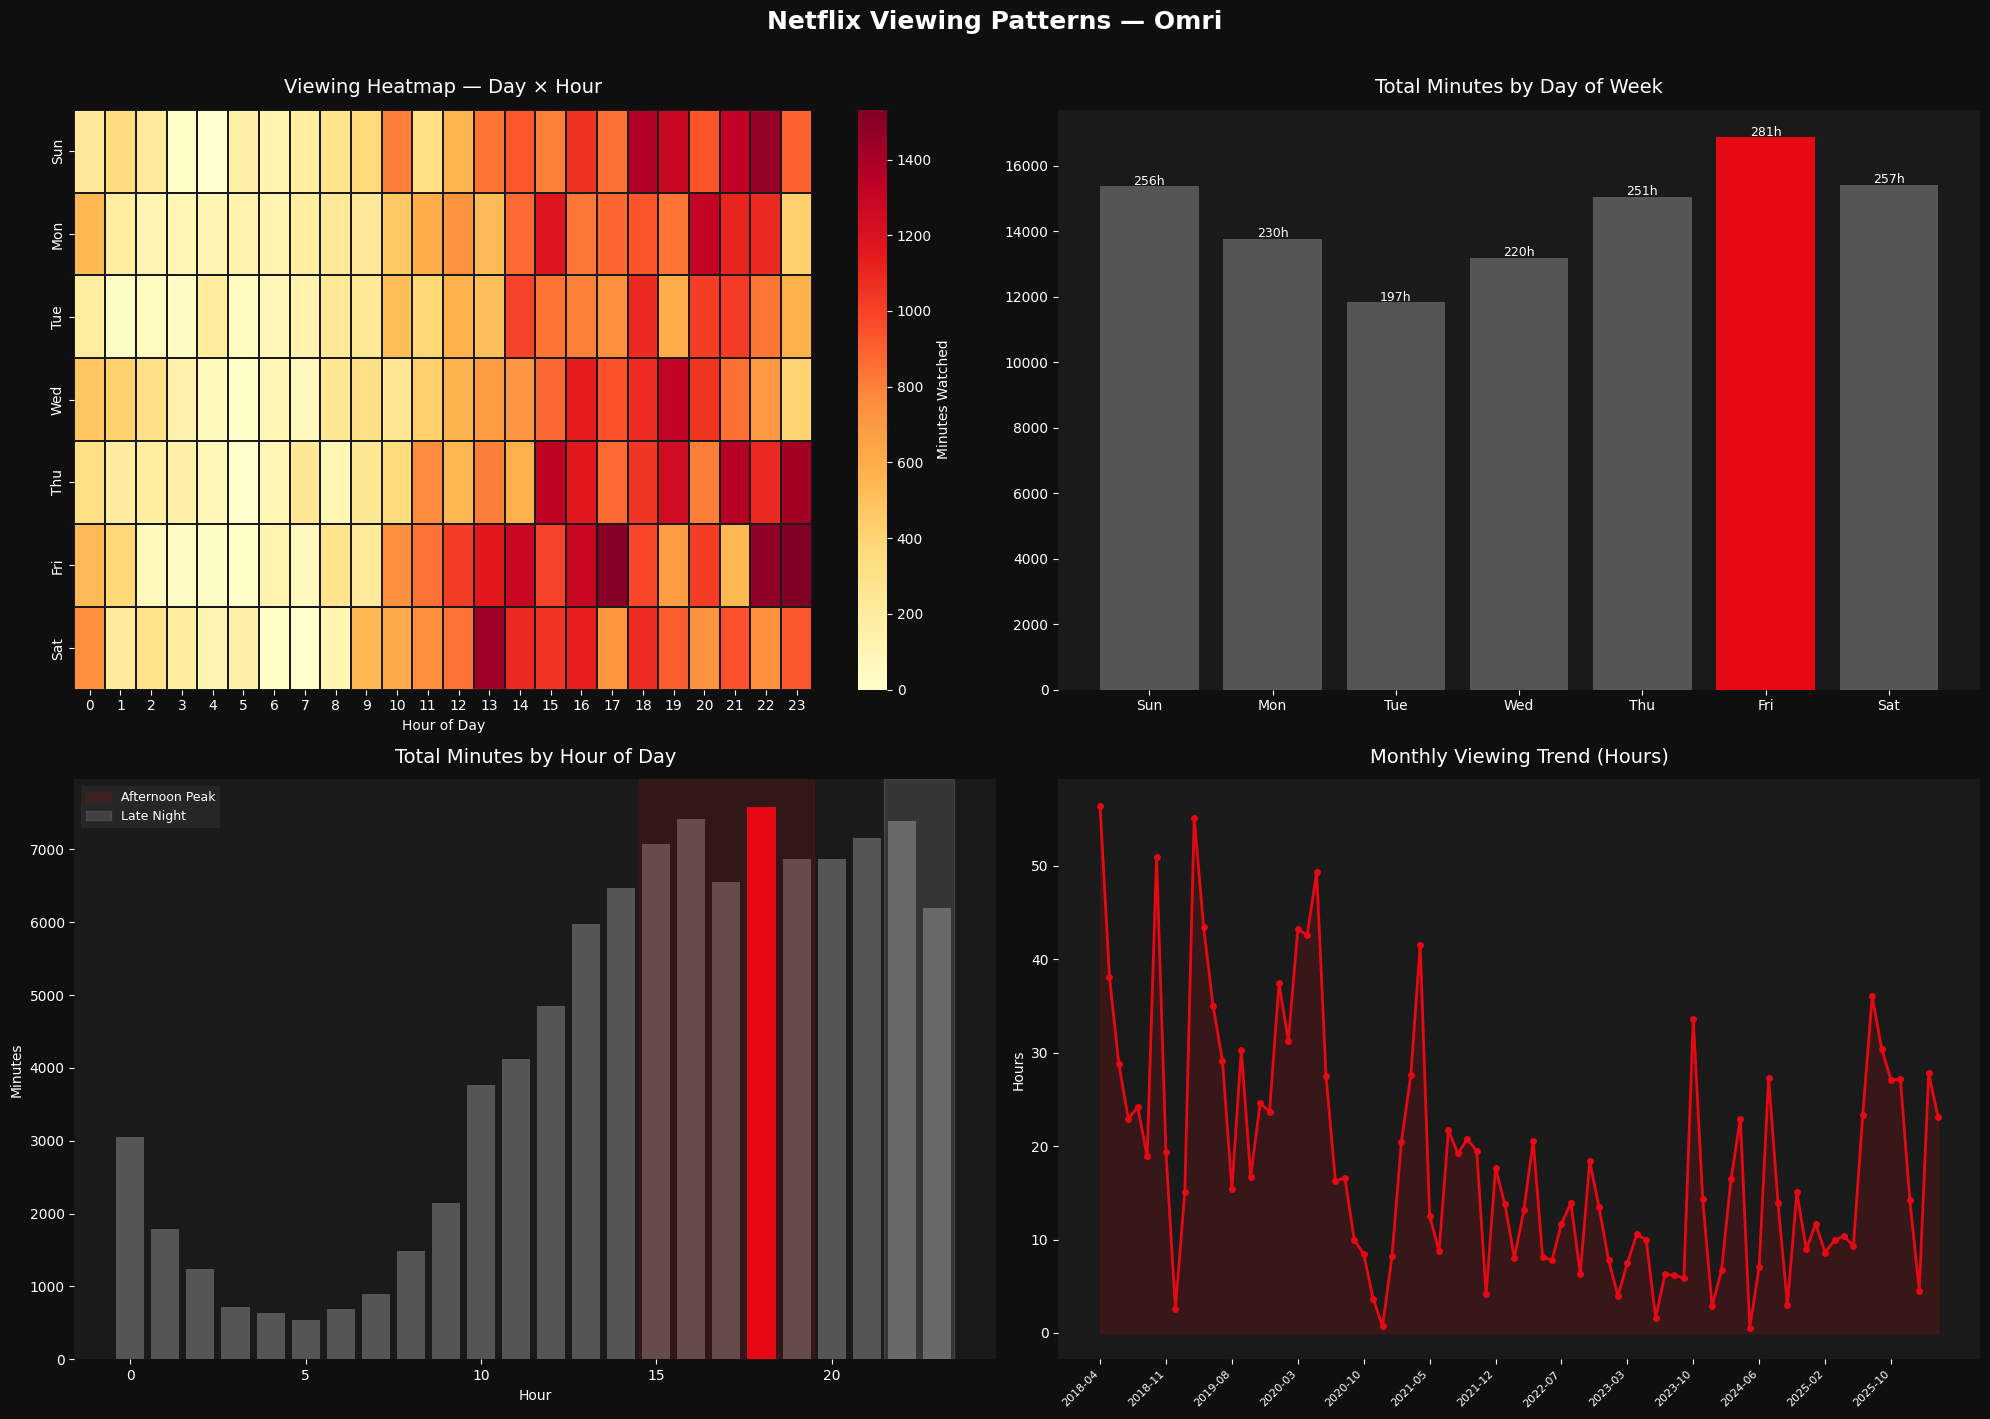

Saved: viewing_patterns.png


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.patch.set_facecolor('#0f0f0f')
netflix_red = '#E50914'

il_day_order_eng = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']

# ── Plot 1: Heatmap ───────────────────────────────────────────────────────────
ax1 = axes[0, 0]
sns.heatmap(
    heatmap_data.reindex(range(7)),
    ax=ax1,
    cmap='YlOrRd',
    linewidths=0.3,
    linecolor='#1a1a1a',
    yticklabels=il_day_order_eng,
    cbar_kws={'label': 'Minutes Watched'}
)
ax1.set_facecolor('#1a1a1a')
ax1.set_title('Viewing Heatmap — Day × Hour', color='white', fontsize=14, pad=12)
ax1.set_xlabel('Hour of Day', color='white')
ax1.set_ylabel('', color='white')
ax1.tick_params(colors='white')
ax1.collections[0].colorbar.ax.yaxis.label.set_color('white')
ax1.collections[0].colorbar.ax.tick_params(colors='white')

# ── Plot 2: Minutes by day of week ────────────────────────────────────────────
ax2 = axes[0, 1]
dow_plot = (
    time_df.groupby('il_dow')['Duration_Min'].sum()
    .reindex(range(7))
)
colors = [netflix_red if v == dow_plot.max() else '#555555' for v in dow_plot.values]
bars = ax2.bar(il_day_order_eng, dow_plot.values, color=colors, edgecolor='none')
ax2.set_facecolor('#1a1a1a')
ax2.set_title('Total Minutes by Day of Week', color='white', fontsize=14, pad=12)
ax2.tick_params(colors='white')
ax2.spines[:].set_visible(False)
for bar, val in zip(bars, dow_plot.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{val/60:.0f}h', ha='center', color='white', fontsize=9)

# ── Plot 3: Minutes by hour ───────────────────────────────────────────────────
ax3 = axes[1, 0]
hour_plot = time_df.groupby('hour')['Duration_Min'].sum().reindex(range(24), fill_value=0)
colors_h  = [netflix_red if v == hour_plot.max() else '#555555' for v in hour_plot.values]
ax3.bar(hour_plot.index, hour_plot.values, color=colors_h, edgecolor='none')
ax3.set_facecolor('#1a1a1a')
ax3.set_title('Total Minutes by Hour of Day', color='white', fontsize=14, pad=12)
ax3.set_xlabel('Hour', color='white')
ax3.set_ylabel('Minutes', color='white')
ax3.tick_params(colors='white')
ax3.spines[:].set_visible(False)
ax3.axvspan(14.5, 19.5, alpha=0.12, color=netflix_red, label='Afternoon Peak')
ax3.axvspan(21.5, 23.5, alpha=0.12, color='white',      label='Late Night')
ax3.legend(facecolor='#2a2a2a', labelcolor='white', fontsize=9, edgecolor='none')

# ── Plot 4: Monthly trend ─────────────────────────────────────────────────────
ax4 = axes[1, 1]
monthly_plot = (
    time_df.groupby(['year', 'month'])['Duration_Min']
    .sum()
    .reset_index()
    .sort_values(['year', 'month'])
    .reset_index(drop=True)
)
monthly_plot['hours']  = monthly_plot['Duration_Min'] / 60
monthly_plot['period'] = (monthly_plot['year'].astype(str) + '-' +
                           monthly_plot['month'].astype(str).str.zfill(2))

x = range(len(monthly_plot))
ax4.plot(x, monthly_plot['hours'], color=netflix_red,
         linewidth=2, marker='o', markersize=4)
ax4.fill_between(x, monthly_plot['hours'], alpha=0.15, color=netflix_red)
ax4.set_facecolor('#1a1a1a')
ax4.set_title('Monthly Viewing Trend (Hours)', color='white', fontsize=14, pad=12)
ax4.set_ylabel('Hours', color='white')
ax4.tick_params(colors='white')
ax4.spines[:].set_visible(False)

step = max(1, len(monthly_plot) // 12)
ax4.set_xticks(list(range(0, len(monthly_plot), step)))
ax4.set_xticklabels(
    monthly_plot['period'].iloc[::step].tolist(),
    rotation=45, ha='right', fontsize=8, color='white'
)

plt.suptitle('Netflix Viewing Patterns — Omri', color='white',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('viewing_patterns.png', dpi=150, bbox_inches='tight',
            facecolor='#0f0f0f')
plt.show()
print("Saved: viewing_patterns.png")

In [12]:
# Add english_name to time_df via merge
time_df = time_df.merge(
    show_df[['show', 'english_name']],
    left_on='Clean_Show_Name', right_on='show',
    how='left'
).drop(columns=['show'])

print(f"time_df shape after merge: {time_df.shape}")
print(time_df[['Clean_Show_Name', 'english_name']].head())

time_df shape after merge: (3515, 39)
  Clean_Show_Name   english_name
0     הדינוזאורים  The Dinosaurs
1      ברידג'רטון     Bridgerton
2      ברידג'רטון     Bridgerton
3      ברידג'רטון     Bridgerton
4         התבגרות    Adolescence


In [13]:
# ── Export CSVs for PowerBI ───────────────────────────────────────────────────

# 1. Main show-level table — one row per show
powerbi_shows = show_df[[
    'show', 'english_name', 'genres', 'rating', 'user_score',
    'num_episodes', 'num_seasons', 'total_minutes', 'num_sessions',
    'completion_ratio', 'raw_completion', 'binge_score', 'avg_daily_eps',
    'max_eps_in_day', 'binge_days', 'date_range_days', 'engagement_score',
    'pacing', 'darkness', 'complexity', 'emotional_intensity',
    'mystery_level', 'realism'
]].copy()
powerbi_shows.to_csv('powerbi_shows.csv', index=False, encoding='utf-8-sig')

# 2. Viewing sessions — one row per session (for heatmap in PowerBI)
powerbi_sessions = time_df[[
    'Clean_Show_Name', 'english_name', 'Duration_Min',
    'Start_IL', 'hour', 'dayofweek', 'il_dow', 'month', 'year', 'date',
    'Device Type', 'Genres', 'Rating'
]].copy()
powerbi_sessions.columns = [
    'show_heb', 'show_eng', 'duration_min',
    'start_time', 'hour', 'dow_mon_based', 'dow_sun_based', 'month', 'year', 'date',
    'device', 'genres', 'rating'
]
# Add readable day name (Sun-first)
il_day_map = {0:'Sunday', 1:'Monday', 2:'Tuesday', 3:'Wednesday',
              4:'Thursday', 5:'Friday', 6:'Saturday'}
powerbi_sessions['day_name'] = powerbi_sessions['dow_sun_based'].map(il_day_map)
powerbi_sessions['start_time'] = powerbi_sessions['start_time'].astype(str)
powerbi_sessions.to_csv('powerbi_sessions.csv', index=False, encoding='utf-8-sig')

# 3. Cluster table
powerbi_clusters = cluster_df[[
    'show', 'english_name', 'engagement_score', 'cluster',
    'pca_x', 'pca_y'
] + thematic_cols].copy()
cluster_labels = {
    0: 'True Crime / Documentary',
    1: 'Family / Comedy',
    2: 'Psychological Thriller',
    3: 'Dark Sci-Fi & Fantasy',
    4: 'Reality / Light'
}
powerbi_clusters['cluster_label'] = powerbi_clusters['cluster'].map(cluster_labels)
powerbi_clusters.to_csv('powerbi_clusters.csv', index=False, encoding='utf-8-sig')

# 4. Genre preference vector
preference_genre_df.to_frame('preference_weight').reset_index()\
    .rename(columns={'index': 'genre'})\
    .to_csv('powerbi_genre_preference.csv', index=False, encoding='utf-8-sig')

# 5. Keyword preference vector (top 40)
preference_kw_df.head(40).to_frame('preference_weight').reset_index()\
    .rename(columns={'index': 'keyword'})\
    .to_csv('powerbi_keyword_preference.csv', index=False, encoding='utf-8-sig')

# 6. Daily summary — for trend charts
powerbi_daily = (
    time_df.groupby('date')
    .agg(
        total_minutes = ('Duration_Min', 'sum'),
        num_sessions  = ('Duration_Min', 'count'),
        num_shows     = ('Clean_Show_Name', 'nunique')
    )
    .reset_index()
)
powerbi_daily.to_csv('powerbi_daily.csv', index=False, encoding='utf-8-sig')

print("PowerBI files exported:")
print("  powerbi_shows.csv       — one row per show, all features")
print("  powerbi_sessions.csv    — one row per viewing session")
print("  powerbi_clusters.csv    — cluster assignments + PCA coords")
print("  powerbi_genre_preference.csv  — genre preference weights")
print("  powerbi_keyword_preference.csv — top 40 keyword weights")
print("  powerbi_daily.csv       — daily viewing summary")

PowerBI files exported:
  powerbi_shows.csv       — one row per show, all features
  powerbi_sessions.csv    — one row per viewing session
  powerbi_clusters.csv    — cluster assignments + PCA coords
  powerbi_genre_preference.csv  — genre preference weights
  powerbi_keyword_preference.csv — top 40 keyword weights
  powerbi_daily.csv       — daily viewing summary


In [15]:
cluster_labels = {
    0: 'True Crime / Documentary',
    1: 'Family / Comedy',
    2: 'Psychological Thriller',
    3: 'Dark Sci-Fi & Fantasy',
    4: 'Reality / Light'
}
cluster_df['cluster_label'] = cluster_df['cluster'].map(cluster_labels)

cluster_summary = cluster_df.groupby('cluster_label').agg(
    avg_engagement=('engagement_score', 'mean'),
    count=('show', 'count')
).round(3).to_dict('index')

print(cluster_summary)

{'Dark Sci-Fi & Fantasy': {'avg_engagement': 0.518, 'count': 65}, 'Family / Comedy': {'avg_engagement': 0.218, 'count': 4}, 'Psychological Thriller': {'avg_engagement': 0.486, 'count': 90}, 'Reality / Light': {'avg_engagement': 0.289, 'count': 20}, 'True Crime / Documentary': {'avg_engagement': 0.399, 'count': 19}}


In [19]:
# ── LLM Natural Language Summary ─────────────────────────────────────────────

# Build a comprehensive profile to send to Claude
thematic_weighted = {
    col: round((show_df[col] * show_df['engagement_score']).sum() / 
                show_df['engagement_score'].sum(), 2)
    for col in thematic_cols
    if show_df[col].notna().any()
}

top_shows = show_df.nlargest(10, 'engagement_score')[
    ['english_name', 'engagement_score', 'rating', 'completion_ratio', 'binge_score']
].to_dict('records')

bottom_shows = show_df.nsmallest(5, 'engagement_score')[
    ['english_name', 'engagement_score']
].to_dict('records')

cluster_summary = cluster_df.groupby('cluster_label').agg(
    avg_engagement = ('engagement_score', 'mean'),
    count          = ('show', 'count')
).round(3).to_dict('index')

top_genres   = preference_genre_df.head(5).round(3).to_dict()
top_keywords = preference_kw_df.head(15).round(3).to_dict()

peak_hour = int(time_df.groupby('hour')['Duration_Min'].sum().idxmax())
peak_day  = time_df.groupby('il_dow')['Duration_Min'].sum().idxmax()
peak_day_name = ['Sunday','Monday','Tuesday','Wednesday',
                 'Thursday','Friday','Saturday'][peak_day]

avg_daily   = round(time_df.groupby('date')['Duration_Min'].sum().mean(), 1)
binge_days  = int((time_df.groupby('date')['Duration_Min'].sum() >= 240).sum())
total_hours = round(time_df['Duration_Min'].sum() / 60, 1)

profile = f"""
You are analyzing the Netflix viewing data of a single user named Omri, 
a computer science student in Israel. Based on the data below, write a 
compelling, insightful personal analysis of his viewing personality.

Be specific, reference actual show names, and draw non-obvious conclusions.
Write in a style that is analytical but engaging — like a data journalist 
writing about a person. Length: 4-6 paragraphs.

=== VIEWING STATS ===
Total hours watched: {total_hours}h
Average minutes per day (on days watched): {avg_daily} min
Days with 4h+ viewing (binge days): {binge_days}
Peak viewing hour: {peak_hour}:00
Peak viewing day: {peak_day_name}

=== TOP 10 SHOWS BY ENGAGEMENT ===
{top_shows}

=== LOWEST ENGAGEMENT SHOWS ===
{bottom_shows}

=== GENRE PREFERENCES (weighted by engagement) ===
{top_genres}

=== TOP KEYWORDS (weighted by engagement) ===
{top_keywords}

=== THEMATIC PROFILE (1-5 scale, weighted by engagement) ===
{thematic_weighted}

=== CONTENT CLUSTERS ===
{cluster_summary}

=== MODEL FINDINGS ===
- Behavioral model R²: 0.978 (how you watch predicts preference almost perfectly)
- Content-only model R²: 0.175 (what you watch is a weaker predictor)
- Key insight: behavioral signals (completion, binge patterns) are 5x stronger 
  predictors than content features (genre, themes)
"""

response = client.messages.create(
    model="claude-sonnet-4-6",
    max_tokens=1500,
    messages=[{"role": "user", "content": profile}]
)

summary = response.content[0].text
print(summary)

# Save to file
with open('viewing_personality_summary.txt', 'w', encoding='utf-8') as f:
    f.write(summary)
print("\nSaved: viewing_personality_summary.txt")

# The Mind That Needs to Know How It Ends: A Data Portrait of Omri

At 1,691 hours of Netflix viewing, Omri has spent the equivalent of over 70 full days — roughly ten full weeks of his life — watching streaming content. That number alone says something, but the *shape* of those hours is far more revealing than the volume. The peak viewing hour of 6 PM and the dominant day of Friday tell a coherent story: this is someone who treats the end of a school week like a controlled decompression chamber. Friday at 6 PM in Israel is the doorstep of Shabbat, a cultural inflection point that separates the week's obligations from personal time, and Omri uses it with precision. He doesn't binge chaotically throughout the week — he front-loads his leisure, watching with the focused intentionality of someone who has earned it. The 26 binge days scattered across his history aren't random impulsive marathons; they cluster around the logic of a student who finishes something hard and needs a world to fa

In [20]:
# Create .gitignore
gitignore_content = """
# Personal Netflix data
ViewingActivity.csv
Ratings.csv

# Derived data files
TMDB_data.csv
merged.csv
show_df.csv
time_df.csv
cluster_df.csv
powerbi_*.csv
preference_*.csv

# API keys
.env

# Python
__pycache__/
*.pyc
.ipynb_checkpoints/

# OS
.DS_Store
Thumbs.db
"""

with open('.gitignore', 'w') as f:
    f.write(gitignore_content.strip())

# Create requirements.txt
requirements_content = """
pandas
numpy
requests
anthropic
python-dotenv
scikit-learn
matplotlib
seaborn
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content.strip())

print("Created .gitignore and requirements.txt")

Created .gitignore and requirements.txt


In [1]:
readme_content = """# Netflix Viewing Behavior — Personal Data Analysis

A full end-to-end data analysis project built on my own Netflix viewing history.
The goal was to reverse-engineer my viewing preferences from raw behavioral data,
using a combination of classical data science tools, external APIs, and LLMs.

---

## Project Structure
├── exploration.ipynb              # Full analysis notebook — iterative process,
│                                  # decisions, dead ends, and reasoning documented
├── analysis.ipynb                 # Clean production notebook — runs end-to-end
├── thematic_profiles_cache.json   # Cached LLM API responses (avoids re-billing)
├── viewing_patterns.png           # Visualization output
├── viewing_personality_summary.txt # LLM-generated personality portrait
└── requirements.txt

> **Note on structure**: This project was developed as a single iterative notebook
> rather than modular scripts. `exploration.ipynb` shows the actual development
> process — including intermediate decisions, threshold tuning, and model comparisons.
> `analysis.ipynb` is the cleaned version that runs sequentially from start to finish.
> The analysis covers the following stages in order:
>
> 1. Data collection & TMDB API enrichment
> 2. Feature engineering (engagement score, binge metrics)
> 3. Preference vectors (genre one-hot, keyword TF-IDF)
> 4. LLM enrichment via Claude API (thematic profiling)
> 5. Modeling & train/test evaluation
> 6. Clustering (K-Means + PCA)
> 7. Time analysis & visualization
> 8. LLM-generated natural language summary

---

## Data Sources

- **Netflix** — Personal viewing history export (`ViewingActivity.csv`, `Ratings.csv`)
  Available at: netflix.com → Account → Download your personal information
  *(Not included in this repo — personal data)*

- **TMDB API** — Metadata enrichment: genres, keywords, cast, episode count, runtime
  Free API key at: themoviedb.org/settings/api

- **Claude API (Anthropic)** — Thematic profiling of shows via natural language analysis

---

## Methodology

### 1. Data Preparation
Merged three data sources: viewing sessions, explicit ratings (Thumbs 0–3),
and TMDB metadata. Handled Hebrew-to-English title mapping for rating joins.
Filtered sessions under 3 minutes (trailers, misclicks).

### 2. Feature Engineering
Built behavioral features that don't exist in the raw data:

| Feature | Description |
|---|---|
| `engagement_score` | Weighted composite: 40% rating + 30% completion + 20% binge + 10% pace |
| `completion_ratio` | Minutes watched / estimated total runtime |
| `binge_score` | Normalized: max episodes in one day + sustained binge days |
| `pace_norm` | Average daily episodes, capped at P90 of distribution |

All caps were set empirically from the actual data distribution (P90/P95),
not from arbitrary assumptions.

### 3. Preference Vectors
- **Genre vector**: One-hot encoding → weighted average by engagement score
- **Keyword vector**: TF-IDF (penalizes common keywords like "based on novel",
  rewards specific ones like "time travel") → weighted average by engagement

### 4. LLM Enrichment
Sent each show's Overview + Keywords to Claude Haiku and received structured
JSON with scores (1–5) on 6 thematic dimensions:
`pacing`, `darkness`, `complexity`, `emotional_intensity`, `mystery_level`, `realism`

Results cached in `thematic_profiles_cache.json` to avoid redundant API calls.

### 5. Modeling
Built and compared two model families:

**With behavioral features (validation):**
→ R² = 0.978 — confirms engagement score is internally consistent,
but suffers from data leakage (behavioral features directly compose the target)

**Content-only features (true prediction, no leakage):**

| Model | R² | MAE |
|---|---|---|
| Ridge Regression (29 features) | 0.262 | 0.222 |
| Ridge Regression (6 thematic only) | 0.125 | 0.246 |
| Random Forest (29 features) | -0.010 | 0.253 |
| Cosine Similarity Engine | 0.199 | 0.219 |

Cross-validation R² (Ridge, 5-fold): -153 — confirms overfitting due to small dataset.

**Key finding:** behavioral signals are ~5× stronger predictors than content signals.
This mirrors findings in production recommendation systems (Netflix, Spotify).
The low content-only R² is itself a meaningful result: viewing taste has dimensions
not captured by metadata alone (acting chemistry, mood, personal context).

### 6. Clustering
K-Means (K=5, selected via Elbow method) on thematic + genre feature matrix.
PCA to 2 components for visualization (34.5% variance explained).

| Cluster | Label | Avg Engagement |
|---|---|---|
| 3 | Dark Sci-Fi & Fantasy | 0.518 |
| 2 | Psychological Thriller | 0.486 |
| 0 | True Crime / Documentary | 0.399 |
| 4 | Reality / Light | 0.289 |
| 1 | Family / Comedy | 0.218 |

### 7. Time Analysis
Extracted viewing patterns by hour, day of week (Israeli Sunday-first week),
month, and device. Peak: Friday 18:00–19:00.

### 8. LLM Summary
Sent the full numerical profile (engagement stats, top shows, preference vectors,
cluster breakdown, model findings) to Claude Sonnet for a natural language
portrait of viewing personality. Output saved in `viewing_personality_summary.txt`.

---

## Key Findings

- **Behavioral > Content**: How you watch predicts preference 5× better than what you watch
- **Top content cluster**: Dark, complex Sci-Fi & Fantasy with high mystery
- **Peak viewing**: Friday evenings — deliberate end-of-week decompression pattern
- **Dominant keywords**: miniseries, thriller, murder, time travel, based on novel
- **Thematic profile**: High emotional intensity (3.9/5) and mystery (3.8/5), lower realism (3.1/5)

---

## Tools & Libraries

| Tool | Usage |
|---|---|
| pandas | Data wrangling, merging, aggregation |
| numpy | Vectorized computation, normalization |
| scikit-learn | TF-IDF, encoding, regression, clustering, PCA |
| matplotlib + seaborn | Custom Netflix-styled visualizations |
| requests | TMDB API calls |
| Anthropic Python SDK | Claude API for LLM enrichment and summary |
| PowerBI | Interactive dashboard (4 pages) |
| python-dotenv | Secure API key management |

---

## Limitations

- **No first-watch isolation**: Cannot separate first viewing from re-watches
- **Small dataset**: 246 unique shows limits model generalizability
- **Single user**: No collaborative filtering possible
- **TMDB coverage**: ~7 shows had no metadata (missing Overview)
- **Content ceiling**: Low content-only R² reflects that taste is shaped by
  factors outside metadata — performance, personal context, timing

---

## Setup

```bash
git clone https://github.com/omrisalem/netflix-viewing-analysis
cd netflix-viewing-analysis
pip install -r requirements.txt
```

Create a `.env` file:
TMDB_API_KEY=your_key_here
ANTHROPIC_API_KEY=your_key_here

Export your Netflix data and place `ViewingActivity.csv` and `Ratings.csv`
in the project root, then run `analysis.ipynb` from top to bottom.

---

## Author
Omri Salem — Computer Science student, Israel
Built as a portfolio project demonstrating end-to-end data analysis skills.
"""

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme_content)

print("README.md created")

README.md created
